# 11주차 평가 재검토: 어떤 조건에서 어떤 정책이 유리한가?

이 노트북은 평가 피드백의 질문을 따라 **기존 결과를 재해석하고 추가 검증을 확인하는 파일**이다. 초기 정책 설명과 7,290회 비교는 [정책 비교 노트북](week11_policy_review.ipynb), 전체 맥락은 [통합 보고서](../docs/week11_experiment.md)를 읽는다. 이 파일은 다른 노트북을 먼저 실행하지 않아도 독립적으로 실행된다.

### 평가 대상과 읽는 순서

| 대상 | 이 노트북에서 하는 평가 |
|---|---|
| 기존 7정책 + block 4정책 = 11개 | 초기 결과의 SLO·비제약 참조 대비 격차 재분석, 정책별 판단 정리 |
| Block LRU evict / T-LRU / Block LRU offload / HotPrefix admission | 추가 환경·장기·도착률·prefill 조건의 비교 |
| GPU 64GiB·Pin-All | 같은 계산/FIFO의 비제약 메모리 참조 |

기존 Watermark·Duration-Aware 등이 새로운 확장 조건에서도 재실행된 것은 아니다. 초기 7,290회와 추가 **1,305회 replay / 1,825개 분석 행**을 구분한다. CPU-free 정책의 환경별 재사용 행은 독립 표본이 아니다.

**기존 지표가 무엇을 보는가 → 개선 여유가 남았는가 → 환경에 따라 순위가 바뀌는가 → 정책 판단이 작동했는가 → 긴 실행에서도 유지되는가 → 절대 지연·처리량 가정 → 정책별 피드백** 순서로 읽는다.

| 피드백 항목 | 현재 상태 |
|---|---|
| 조건·부하별 환경 비교 | 대표 두 조건의 PCIe·CPU 축 확장 |
| 평가 지표 개선 | 복귀·참조 격차·완료율 중심, 절대 지연 기준은 예시 |
| 충분한 실행 기간 | 900초·warm-up 300초 및 구간 비교; 정상 상태 완전 입증은 아님 |
| 처리량 실측 | 미수행; 가정 민감도만 평가 |
| 미복귀·도구별 긴 꼬리·공유 prefix | 미도입 |
| 실제 엔진 검증 | 미수행 |

모든 수치는 현재 시뮬레이터 안의 결과다. 성능의 보편적 순위나 실제 GPU 용량으로 일반화하지 않는다.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "docs/data/week11_revision/summary.csv").exists())
DATA = ROOT / "docs/data/week11"
RDATA = ROOT / "docs/data/week11_revision"
initial = pd.read_csv(DATA / "summary.csv")
audit = pd.read_csv(RDATA / "summary.csv")
audit_pairs = pd.read_csv(RDATA / "paired.csv")
initial_manifest = json.loads((DATA / "experiment.json").read_text(encoding="utf-8"))
audit_manifest = json.loads((RDATA / "experiment.json").read_text(encoding="utf-8"))
audit_checks = json.loads((RDATA / "validation.json").read_text(encoding="utf-8"))
for directory, manifest in ((DATA, initial_manifest), (RDATA, audit_manifest)):
    assert manifest["status"] == "complete"
    assert hashlib.sha256((directory / "summary.csv").read_bytes()).hexdigest() == manifest["summary_sha256"]
assert len(initial) == initial_manifest["completed_runs"] == 7290
assert len(audit) == audit_manifest["analysis_rows"] == audit_manifest["planned_analysis_rows"]
assert int(audit.physical_replay.sum()) == audit_manifest["physical_replays"] == 1305
assert audit_checks.get("evaluated_sources_verified", audit_checks.get("source_hashes_match", False))
CORE = ["prefix_lru_evict", "tlru", "prefix_lru_offload", "hotprefix_admission"]
LABELS = {
    "pin_all": "Pin-All", "evict_recompute": "Evict/Recompute", "fixed_ttl": "Fixed TTL",
    "lru_offload": "Legacy LRU offload", "duration_aware": "Duration-Aware",
    "watermark_offload": "Watermark offload", "pin_all_capped": "Capped Pin-All",
    "prefix_lru_evict": "Block LRU evict", "tlru": "T-LRU",
    "prefix_lru_offload": "Block LRU offload", "hotprefix_admission": "HotPrefix admission"}
print("초기:", len(initial), "runs / 추가:", audit_manifest["physical_replays"], "replays")
print("확장 조건에서 기존 replay와 요청·점유율 hash 일치:", audit_checks["identical_original_replays"])
print("정리 전 실행 계획·runner 보존본으로 검증한 경로:", audit_checks.get("archived_source_paths", []))
display(audit.groupby("suite").agg(analysis_rows=("variant", "size"),
                                  physical_replays=("physical_replay", "sum")))

초기: 7290 runs / 추가: 1305 replays
확장 조건에서 기존 replay와 요청·점유율 hash 일치: 280
정리 전 실행 계획·runner 보존본으로 검증한 경로: ['docs/week11_revision_plan.md', 'scripts/run_week11_revision.py']


,analysis_rows,physical_replays
suite,,
environment,880,480
long,390,270
prefill,150,150
reference,405,405


## 1. 기존 평가지표는 무엇을 구분하고 있었나?

기존 상대 SLO는 자기 정책의 W0 대비 normal P95 3배·normal 거절률 10%·Peak 90%를 함께 요구했다. Peak 제약 통과와 실제 서비스 지연을 분리해서 본다. 아래 SLO 재분석은 **기존 11개 정책 결과**에 적용한 것이며 새 조건의 실행을 뜻하지 않는다.

normal 지연 성분은 각 run의 실제 P95 요청에서 구한 뒤 평균낸 값이다. 독립적인 성분별 P95를 더한 것이 아니다. 공유 prefill 대기는 KV 재계산뿐 아니라 긴 첫 prompt·burst에도 영향을 받으므로 normal TTFT는 보조로 함께 읽는다.

In [2]:
main = initial[initial.suite == "main"]
failed = ~main.legacy_all_slo_pass
peak_failed = main.peak_kv_occupancy_pct.gt(90)
only_peak = failed & peak_failed & main.ttft_ratio_vs_policy_w0.le(3) & main.normal_reject_rate_pct.le(10)
print(f"기존 SLO 실패 중 Peak 포함: {100*(failed & peak_failed).sum()/failed.sum():.1f}%")
print(f"기존 SLO 실패 중 Peak만 실패: {100*only_peak.sum()/failed.sum():.1f}%")
slo_review = pd.read_csv(RDATA / "slo_reassessment.csv")
display(slo_review[slo_review.setting == "180s_02"].replace({"variant": LABELS}))
normal_parts = pd.read_csv(RDATA / "normal_tail_components.csv")
display(normal_parts.replace({"variant": LABELS}).round(3))

기존 SLO 실패 중 Peak 포함: 88.3%
기존 SLO 실패 중 Peak만 실패: 73.8%


,setting,variant,runs,legacy_slo_passes,identical_reference_requests,identical_reference_but_slo_fails
0,180s_02,Duration-Aware,135,14,1,0
1,180s_02,Evict/Recompute,135,98,0,0
2,180s_02,Fixed TTL,135,31,0,0
3,180s_02,HotPrefix admission,135,5,15,10
4,180s_02,Legacy LRU offload,135,5,15,10
5,180s_02,Pin-All,135,5,15,10
6,180s_02,Capped Pin-All,135,24,5,0
7,180s_02,Block LRU evict,135,5,15,10
8,180s_02,Block LRU offload,135,5,15,10
9,180s_02,T-LRU,135,5,15,10


,variant,normal_p95_ttft_ms,normal_p95_admission_ms,normal_p95_restore_ms,normal_p95_prefill_queue_ms,normal_p95_self_prefill_ms
0,HotPrefix admission,292.495,3.830,0.0,248.538,40.126
1,Legacy LRU offload,270.057,0.925,0.0,229.626,39.506
2,Block LRU evict,385.223,0.000,0.0,344.148,41.075
3,Block LRU offload,270.450,1.859,0.0,228.683,39.907
4,T-LRU,342.587,0.000,0.0,301.241,41.345


## 2. 메모리가 충분한 경우와 얼마나 차이가 나는가?

동일한 계산/FIFO에서 **GPU KV 풀 64GiB·Pin-All**을 실행했다. GPU가 차거나 요청이 거절되지 않았음을 확인했다. 이 참조는 메모리 제약을 완화한 비교값이며 이론적 최저 지연이 아니다. 요청 순서가 달라지는 정책은 일부 P95가 참조보다 낮을 수도 있다.

표에는 기존 7개를 포함한 11개 정책을 모두 넣었다. 그림은 같은 block 엔진의 핵심 네 정책을 보여준다. 원래 세 설정·9조건·15seed의 run별 복귀 P95와 그 격차를 평균낸 값이다.

비제약 참조와 요청 기록이 같아도 기존 SLO에서 실패한 정책별 run 합계: 259


setting,180s_02,180s_03,60s_02
참조 대비 복귀 P95 격차(ms),,,
Duration-Aware,16.951,36.696,20.610
Evict/Recompute,931.464,1190.472,769.297
Fixed TTL,867.832,2219.236,644.910
HotPrefix admission,114.024,191.309,57.249
Legacy LRU offload,30.240,50.396,18.112
Pin-All,23013.801,27549.668,10595.430
Capped Pin-All,25421.111,29021.302,14815.872
Block LRU evict,381.059,694.682,159.056
Block LRU offload,17.941,31.736,12.441


,variant,reference_resume_p95_ms,resume_p95_ms,resume_p95_ms_gap_ms
0,Duration-Aware,166.208,183.159,16.951
1,Evict/Recompute,166.208,1097.672,931.464
2,Fixed TTL,166.208,1034.039,867.832
3,HotPrefix admission,166.208,280.232,114.024
4,Legacy LRU offload,166.208,196.448,30.240
5,Pin-All,166.208,23180.009,23013.801
6,Capped Pin-All,166.208,25587.319,25421.111
7,Block LRU evict,166.208,547.266,381.059
8,Block LRU offload,166.208,184.149,17.941
9,T-LRU,166.208,450.189,283.981


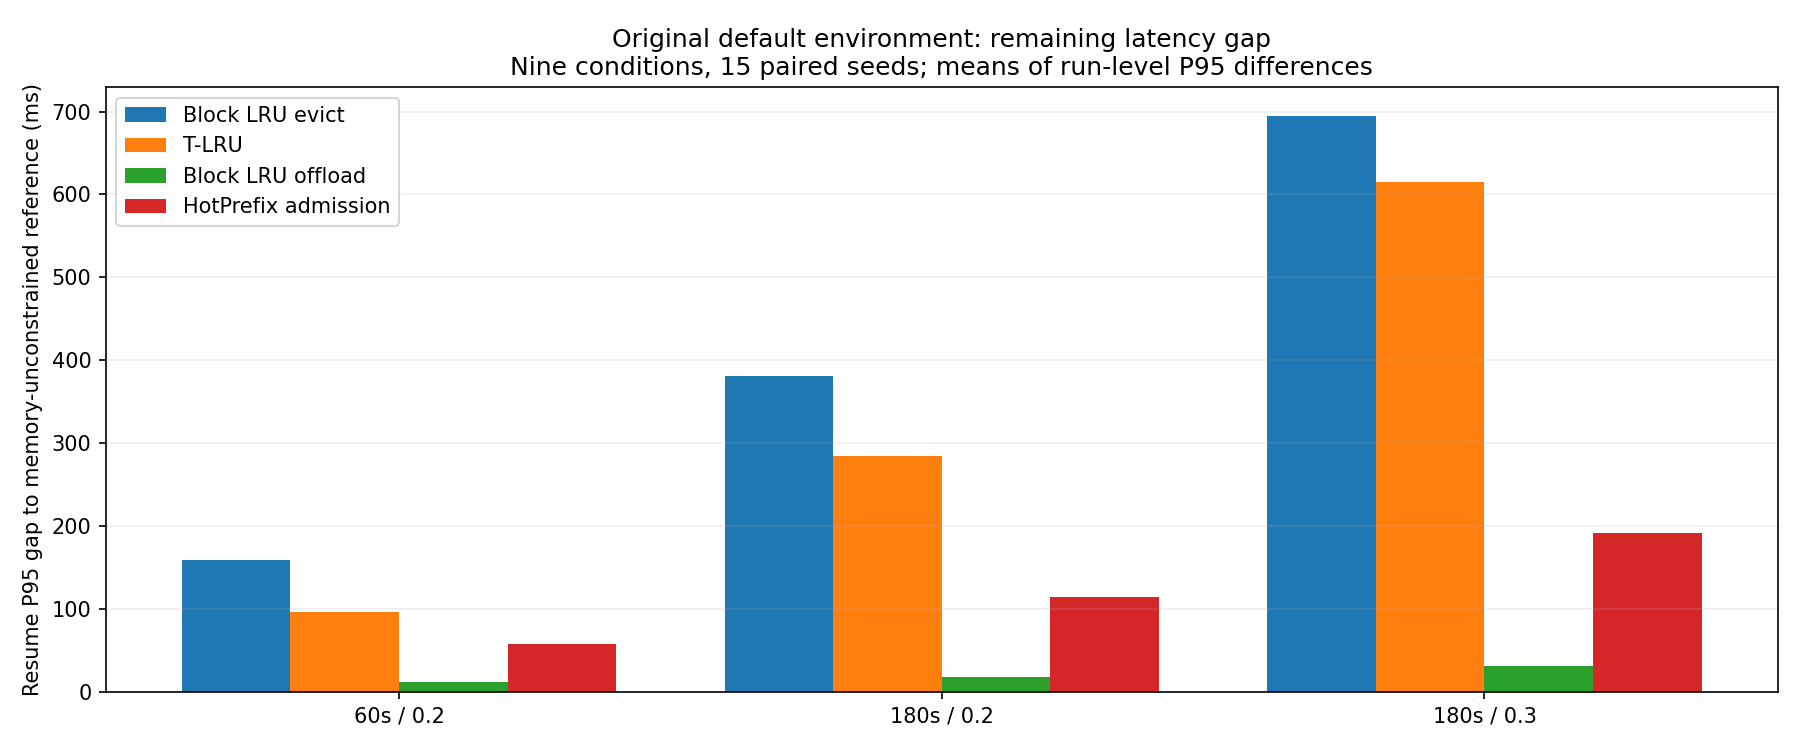

In [3]:
headroom = pd.read_csv(RDATA / "headroom_summary.csv")
gap_table = headroom.pivot(index="variant", columns="setting", values="resume_p95_ms_gap_ms")
display(gap_table.rename(index=LABELS).round(3).rename_axis("참조 대비 복귀 P95 격차(ms)"))
display(headroom[headroom.setting == "180s_02"][
    ["variant", "reference_resume_p95_ms", "resume_p95_ms", "resume_p95_ms_gap_ms"]
].replace({"variant": LABELS}).round(3))
display(Image(filename=str(ROOT / "docs/figures/week11_revision_reference.png")))
print("비제약 참조와 요청 기록이 같아도 기존 SLO에서 실패한 정책별 run 합계:",
      int(slo_review.identical_reference_but_slo_fails.sum()))

## 3. 환경·부하에 따라 정책 순위가 바뀌는가?

180초의 **base_4x·both_4x**, stress 0.2/0.3을 분리하고 seed 0–4를 짝비교한다. PCIe 12→0.3GB/s 축은 CPU 64GiB, CPU 64→0.5GiB 축은 PCIe 12GB/s를 고정했다. 6×6 전체 교차가 아니다.

가로·세로는 로그축이다. 음영은 seed bootstrap 평균의 95% CI이고, 정책 간 차이의 CI는 paired.csv를 따른다. 교차점 표는 평균 짝차이 부호가 바뀐 인접 시험 구간이며 정확한 경계값을 보간하지 않는다.

검정 ×는 한 seed 이상에서 **사용자 요청 거절**이 발생한 지점이다. KV의 CPU admission 거절과 다르다. 이때 완료 요청만의 P95와 완료율을 함께 확인한다.

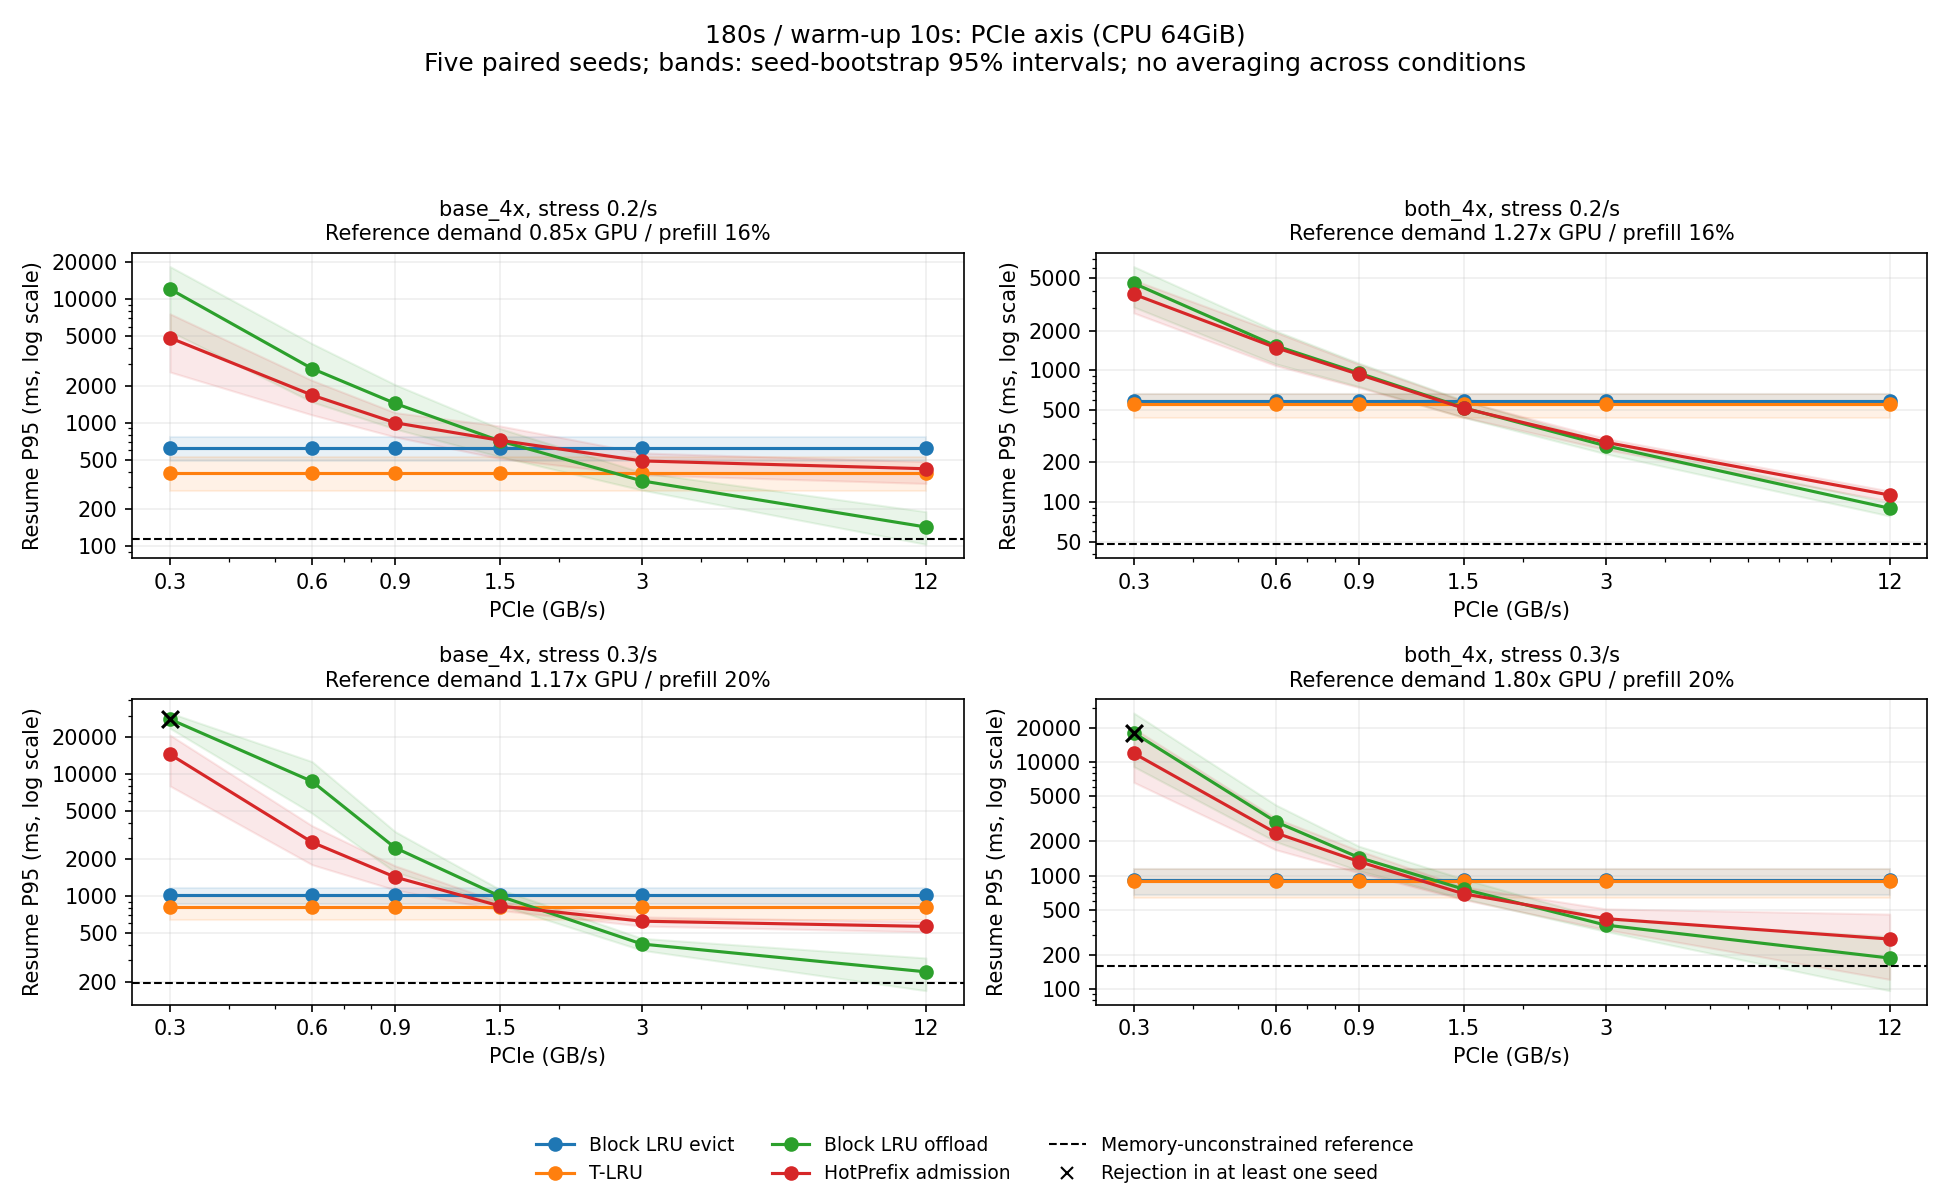

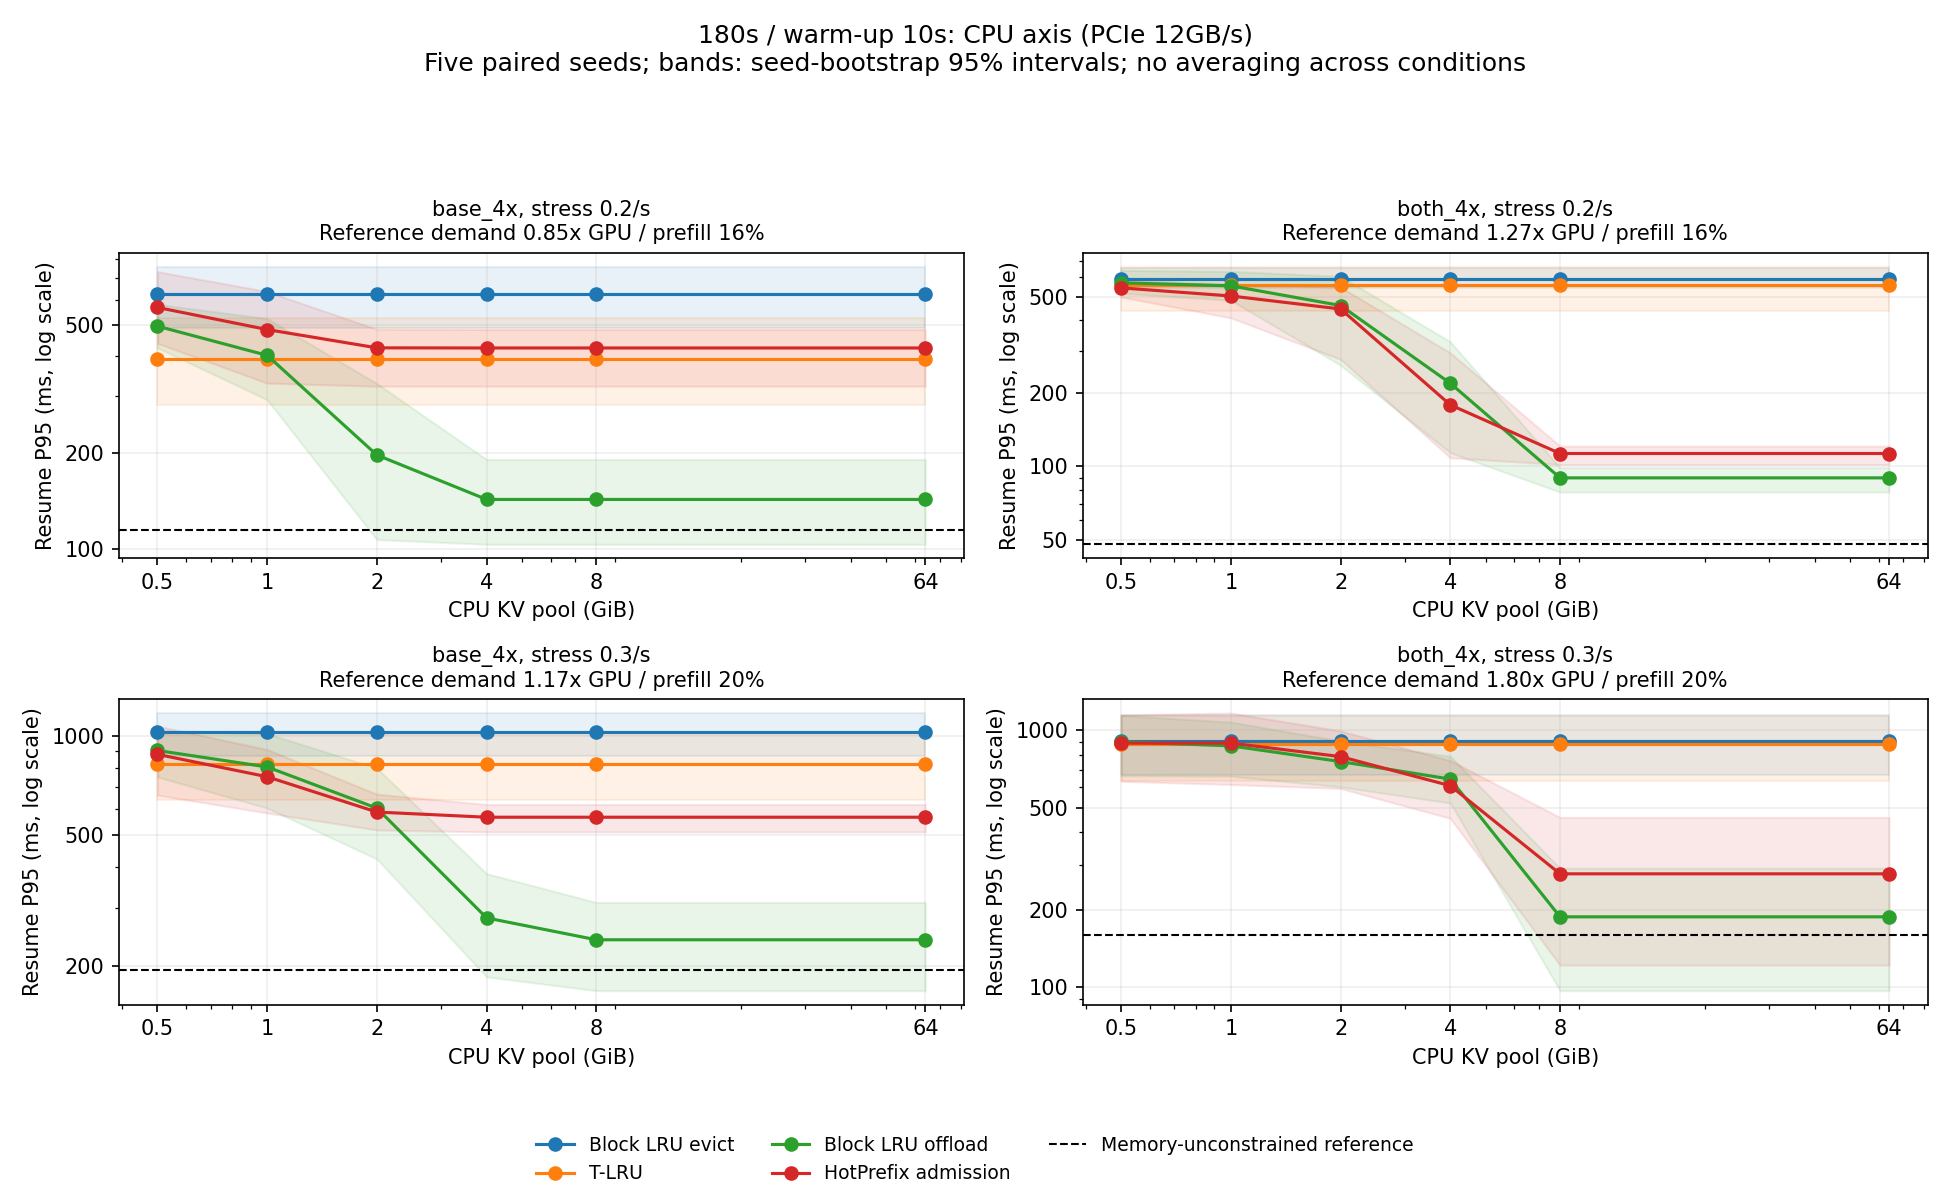

,setting,condition,candidate,baseline,pcie_left_gbps,pcie_right_gbps,left_delta_ms,right_delta_ms,left_ci_low,left_ci_high,right_ci_low,right_ci_high
0,180s_02,base_4x,hotprefix_admission,prefix_lru_evict,1.5,3.0,93.851,-135.844,-12.307,204.789,-192.405,-72.182
1,180s_02,base_4x,hotprefix_admission,prefix_lru_offload,0.9,1.5,-433.676,7.848,-835.410,-132.291,-51.085,61.884
2,180s_02,base_4x,prefix_lru_offload,prefix_lru_evict,1.5,3.0,86.003,-288.056,24.931,153.017,-370.982,-195.975
3,180s_02,base_4x,tlru,prefix_lru_offload,1.5,3.0,-321.157,52.902,-481.540,-192.807,-15.528,136.015
4,180s_02,both_4x,hotprefix_admission,prefix_lru_evict,0.9,1.5,341.986,-73.899,191.684,466.624,-116.143,-36.901
5,180s_02,both_4x,hotprefix_admission,prefix_lru_offload,1.5,3.0,-4.506,16.945,-15.935,5.164,12.945,21.587
6,180s_02,both_4x,hotprefix_admission,tlru,0.9,1.5,375.297,-40.588,249.282,464.192,-102.501,63.397
7,180s_02,both_4x,prefix_lru_offload,prefix_lru_evict,0.9,1.5,364.549,-69.392,204.584,492.045,-121.308,-20.966
8,180s_02,both_4x,tlru,prefix_lru_offload,0.9,1.5,-397.860,36.081,-495.404,-262.182,-65.434,102.808
9,180s_03,base_4x,hotprefix_admission,prefix_lru_evict,0.9,1.5,407.562,-193.533,238.097,609.124,-295.862,-94.107


,setting,condition,variant,pcie_gbps,cpu_gib,stress_completion_pct_mean,stress_completion_pct_min,normal_reject_rate_pct_max
110,180s_03,base_4x,prefix_lru_offload,0.3,64.0,88.500,74.138,1.258
154,180s_03,both_4x,prefix_lru_offload,0.3,64.0,95.517,77.586,0.000


In [4]:
display(Image(filename=str(ROOT / "docs/figures/week11_revision_pcie.png")))
display(Image(filename=str(ROOT / "docs/figures/week11_revision_cpu.png")))
crossings = pd.read_csv(RDATA / "crossing_brackets.csv")
display(crossings.round(3))
outcomes = pd.read_csv(RDATA / "environment_outcomes.csv")
display(outcomes[(outcomes.stress_completion_pct_min < 100)
                 | (outcomes.normal_reject_rate_pct_max > 0)].round(3))

## 4. 정책의 어떤 판단이 실제로 작동했나?

큰 CPU 풀에서는 경쟁·교체가 거의 없어 HotPrefix 결과가 주로 빈도 F=2 필터를 반영할 수 있다. 작은 CPU에서 hotness 거절·resident 교체가 실제 발생하는지 구분한다. 아래 카운터는 전체 replay의 block 결정 수이며 독립 표본 수는 seed다.

사용률은 drain 포함 기존 지표와 서비스 구간을 측정 창에 잘라 계산한 지표를 구분한다. 부하는 비제약 참조의 prefill 사용률·평균 GPU 수요/4GiB도 함께 확인한다.

In [5]:
mechanisms = pd.read_csv(RDATA / "mechanisms.csv").fillna(0)
focus = mechanisms[(mechanisms.variant == "hotprefix_admission")
                   & (mechanisms.pcie_gbps == 12) & mechanisms.cpu_gib.isin([64, 1])]
columns = ["setting", "condition", "cpu_gib", "cpu_peak_gib", "cpu_admission_decisions",
           "cpu_admission_reason_frequency", "cpu_admission_frequency_first_wait",
           "cpu_admission_reason_hotness", "cpu_admission_reason_replace_cpu_coldest"]
display(focus.reindex(columns=columns, fill_value=0).round(3))
usage = audit[(audit.suite == "environment") & (audit.variant == "prefix_lru_offload")
              & (audit.pcie_gbps == 12) & (audit.cpu_gib == 64)]
display(usage.groupby(["setting", "condition"])[
    ["prefill_busy_pct", "prefill_measurement_busy_pct",
     "pcie_busy_pct", "pcie_measurement_busy_pct", "cpu_peak_gib"]].mean().round(3))
resource_demand = pd.read_csv(RDATA / "resource_demand.csv")
display(resource_demand[resource_demand.duration_ms.isin([180000, 900000])
                        & resource_demand.prefill_rate.eq(8000)
                        & resource_demand.stress_rate.isin([0.2, 0.3])
                        & resource_demand.condition.isin(["base_4x", "both_4x"])].round(3))

,setting,condition,cpu_gib,cpu_peak_gib,cpu_admission_decisions,cpu_admission_reason_frequency,cpu_admission_frequency_first_wait,cpu_admission_reason_hotness,cpu_admission_reason_replace_cpu_coldest
24,180s_02,base_4x,1.0,1.000,6614.6,2362.4,1980.4,440.8,673.6
40,180s_02,base_4x,64.0,1.681,6610.4,2359.8,1982.8,0.0,0.0
68,180s_02,both_4x,1.0,1.000,6162.2,439.8,0.0,716.0,3312.6
84,180s_02,both_4x,64.0,3.813,6155.4,437.8,0.0,0.0,0.0
112,180s_03,base_4x,1.0,1.000,19241.6,7171.8,6227.8,2187.0,2980.4
128,180s_03,base_4x,64.0,2.808,18853.8,7120.6,6194.8,0.0,0.0
156,180s_03,both_4x,1.0,1.000,13181.6,1457.0,585.6,2966.8,6406.8
172,180s_03,both_4x,64.0,6.439,12751.2,1303.4,444.8,0.0,0.0


prefill_busy_pct  ...  cpu_peak_gib
setting condition                    ...              
180s_02 base_4x              11.644  ...         2.054
        both_4x               9.624  ...         4.111
180s_03 base_4x              14.076  ...         3.707
        both_4x              11.640  ...         6.856

[4 rows x 5 columns]

,suite,setting,duration_ms,warmup_ms,stress_rate,condition,prefill_rate,reference_memory_demand_ratio,prefill_measurement_busy_pct,gpu_measurement_mean_pct,resume_measurement_p95_ms
1,long,180s_02,900000,300000,0.2,base_4x,8000,0.936,17.192,5.852,188.710
2,long,180s_02,900000,300000,0.2,both_4x,8000,1.558,17.197,9.739,151.455
3,long,180s_02,900000,300000,0.3,base_4x,8000,1.382,21.495,8.640,263.085
4,long,180s_02,900000,300000,0.3,both_4x,8000,2.347,21.488,14.667,387.124
8,prefill,180s_02,180000,10000,0.2,base_4x,8000,0.852,16.463,5.326,157.648
11,prefill,180s_02,180000,10000,0.2,both_4x,8000,1.273,16.351,7.958,54.085
13,reference,180s_02,180000,10000,0.2,base_4x,8000,0.873,16.971,5.454,196.864
15,reference,180s_02,180000,10000,0.2,both_4x,8000,1.302,16.874,8.139,128.528
22,reference,180s_03,180000,10000,0.3,base_4x,8000,1.207,20.697,7.546,253.293
24,reference,180s_03,180000,10000,0.3,both_4x,8000,1.831,20.556,11.443,241.157


## 5. 긴 실행에서도 유지되는가?

900초·warm-up 300초다. 그림의 복귀 window P95는 **도구 종료 시각이 [300,900)초인 요청**의 값이다. 최초 도착 cohort의 resume_p95_ms와 분모가 다르므로 두 짝차이를 함께 본다.

전반 [300,600)과 후반 [600,900) 비교도 제시한다. 외부 도착이 900초에 멈춰 직전 복귀에는 drain 경계 영향이 남을 수 있다. 긴 실행만으로 정상 상태를 입증한 것은 아니다.

base_4x·0.3/s의 세 환경은 대표 사례다. 이 사례에서는 모든 seed의 stress 완료율 100%·normal 거절률 0%였으며, 모든 조건이 같은 순위라는 뜻은 아니다.

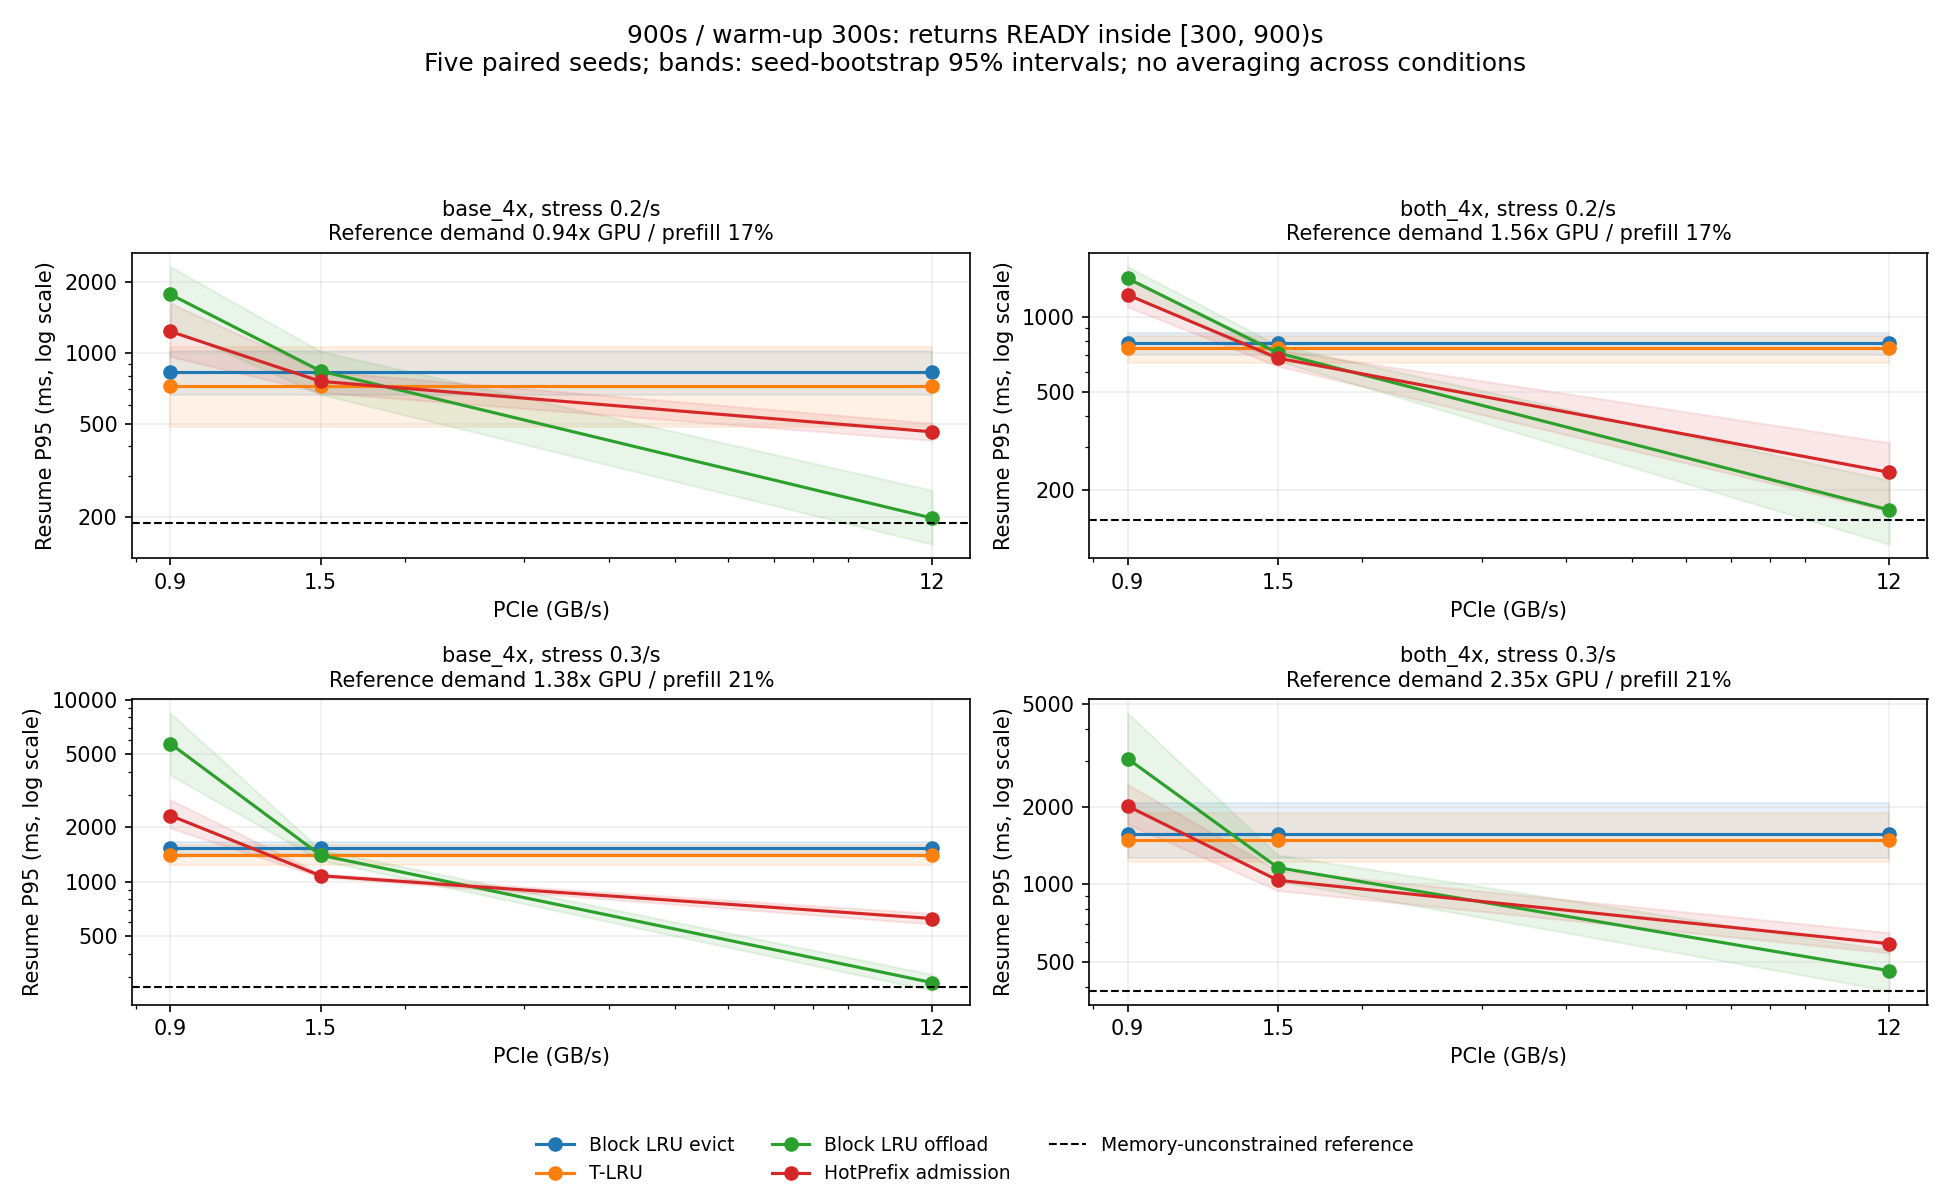

,pcie_gbps,Block LRU evict,T-LRU,Block LRU offload,HotPrefix admission
0,12.0,1532.892,1406.028,277.924,625.950
1,1.5,1532.892,1406.028,1396.212,1076.010
2,0.9,1532.892,1406.028,5734.386,2305.654


,condition,stress_rate,resume_p95_ms_delta,resume_p95_ms_ci_low,resume_p95_ms_ci_high,resume_measurement_p95_ms_delta,resume_measurement_p95_ms_ci_low,resume_measurement_p95_ms_ci_high
294,base_4x,0.2,-109.674,-194.387,47.766,-109.837,-196.770,44.010
312,both_4x,0.2,-22.135,-46.266,1.996,-36.301,-51.736,-21.724
330,base_4x,0.3,-133.534,-194.518,-51.340,-126.864,-187.290,-46.864
348,both_4x,0.3,-79.702,-196.868,2.475,-86.877,-191.087,-25.401


,condition,stress_rate,pcie_gbps,variant,early_window_p95_mean_ms,late_window_p95_mean_ms,late_minus_early_ms,ci_low,ci_high,seeds
11,base_4x,0.2,12.0,prefix_lru_offload,219.540,184.027,-35.513,-70.189,-3.869,5
12,base_4x,0.2,12.0,tlru,794.631,591.332,-203.299,-465.939,44.551,5
24,base_4x,0.3,12.0,prefix_lru_offload,269.544,288.871,19.327,-36.026,54.133,5
25,base_4x,0.3,12.0,tlru,1367.130,1295.201,-71.929,-631.476,474.089,5
37,both_4x,0.2,12.0,prefix_lru_offload,173.857,203.515,29.658,-88.676,158.719,5
38,both_4x,0.2,12.0,tlru,743.763,763.207,19.444,-279.160,303.408,5
50,both_4x,0.3,12.0,prefix_lru_offload,443.755,459.611,15.856,-215.373,263.879,5
51,both_4x,0.3,12.0,tlru,1553.783,1284.814,-268.968,-1090.025,292.730,5


In [6]:
display(Image(filename=str(ROOT / "docs/figures/week11_revision_long.png")))
regimes = pd.read_csv(RDATA / "regime_summary.csv")
display(regimes.rename(columns=LABELS).round(3))
long_effects = audit_pairs[(audit_pairs.suite == "long") & (audit_pairs.pcie_gbps == 12)
                          & audit_pairs.stress_rate.isin([0.2, 0.3])
                          & (audit_pairs.candidate == "tlru")
                          & (audit_pairs.baseline == "prefix_lru_evict")]
display(long_effects[["condition", "stress_rate", "resume_p95_ms_delta",
                      "resume_p95_ms_ci_low", "resume_p95_ms_ci_high",
                      "resume_measurement_p95_ms_delta", "resume_measurement_p95_ms_ci_low",
                      "resume_measurement_p95_ms_ci_high"]].round(3))
stability = pd.read_csv(RDATA / "stability.csv")
display(stability[(stability.pcie_gbps == 12)
                  & stability.variant.isin(["tlru", "prefix_lru_offload"])].round(3))

## 6. 절대 지연 기준을 만족하는 시험 도착률은?

both_4x, 900초·warm-up 300초에서 stress 도착률 0.1/0.2/0.3/0.4를 비교했다. normal 도착률은 2/s로 고정했다.

예시 기준은 normal·복귀 window P95 각각 500ms 또는 각각 1,000ms, stress cohort 완료율 ≥99%, normal 거절률 ≤1%다. 서비스의 확정 SLO가 아니다. 최대 통과값은 모든 5seed가 통과한 **시험 격자점**이다. 통과점 없음은 용량 0을 뜻하지 않고, 상단 미확정이나 비단조 결과는 별도 표시한다. 평균 P95만 기준 아래라고 모든 seed가 통과한 것은 아니다.

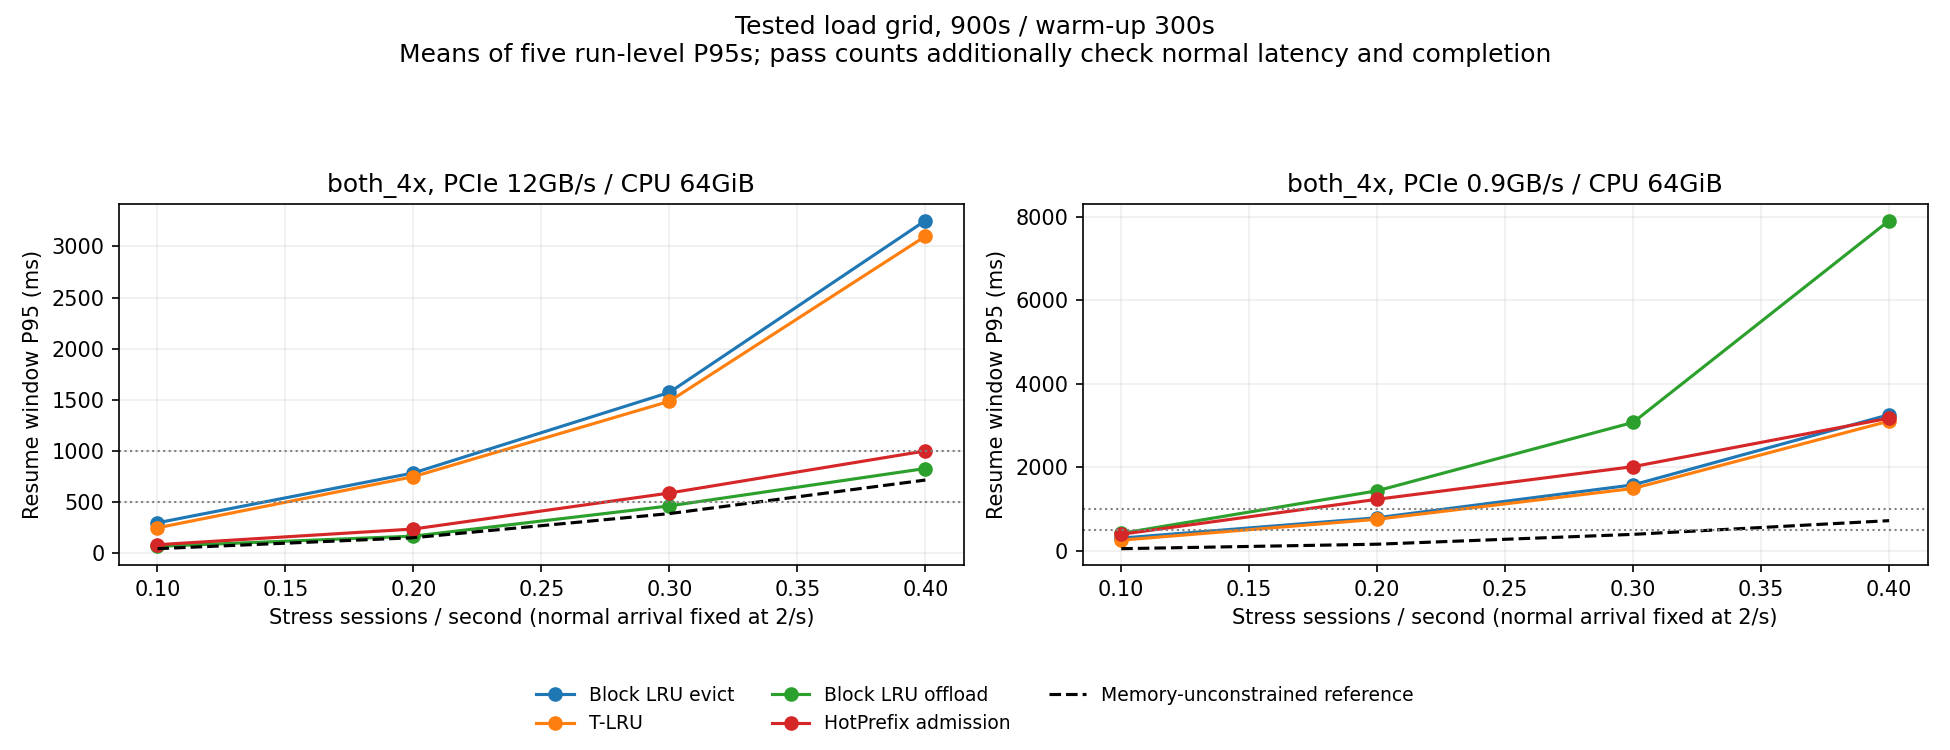

,budget_ms,pcie_gbps,variant,max_tested_passing_rate,highest_tested_rate,upper_boundary_censored,lower_boundary_censored,non_monotone
0,500,0.9,HotPrefix admission,NaN,0.4,False,True,False
1,500,0.9,Block LRU evict,NaN,0.4,False,True,False
2,500,0.9,Block LRU offload,NaN,0.4,False,True,False
3,500,0.9,T-LRU,0.1,0.4,False,False,False
4,500,12.0,HotPrefix admission,0.2,0.4,False,False,False
5,500,12.0,Block LRU evict,NaN,0.4,False,True,False
6,500,12.0,Block LRU offload,0.2,0.4,False,False,False
7,500,12.0,T-LRU,0.1,0.4,False,False,False
8,1000,0.9,HotPrefix admission,0.1,0.4,False,False,False
9,1000,0.9,Block LRU evict,0.2,0.4,False,False,False


,variant,stress_rate,passed_seeds,seeds,all_seeds_pass
16,HotPrefix admission,0.1,5,5,True
17,HotPrefix admission,0.2,5,5,True
18,HotPrefix admission,0.3,0,5,False
19,HotPrefix admission,0.4,0,5,False
20,Block LRU evict,0.1,4,5,False
21,Block LRU evict,0.2,0,5,False
22,Block LRU evict,0.3,0,5,False
23,Block LRU evict,0.4,0,5,False
24,Block LRU offload,0.1,5,5,True
25,Block LRU offload,0.2,5,5,True


In [7]:
display(Image(filename=str(ROOT / "docs/figures/week11_revision_capacity.png")))
capacity_limits = pd.read_csv(RDATA / "capacity_limits.csv")
display(capacity_limits.drop(columns="interpretation").replace({"variant": LABELS}))
capacity_grid = pd.read_csv(RDATA / "capacity_grid.csv")
display(capacity_grid[(capacity_grid.budget_ms == 500)
                      & (capacity_grid.pcie_gbps == 12)][
    ["variant", "stress_rate", "passed_seeds", "seeds", "all_seeds_pass"]
].replace({"variant": LABELS}))

## 7. prefill 가정을 바꾸면 결론이 유지되는가?

8,000/4,000/2,000 tokens/s를 시험하고 비제약 참조도 같은 속도로 다시 실행했다. 모두 가정값이다. 계산 병목이 달라질 때 참조와의 격차도 함께 봐야 한다.

실측에서는 모델·정밀도·문맥·batch를 기록하고 prefill·decode·양방향 copy service 시간을 동기화 후 측정해야 한다. 현재 고정 decode·FIFO·전송/계산 독립 가정은 실제 장치 검증을 기다린다.

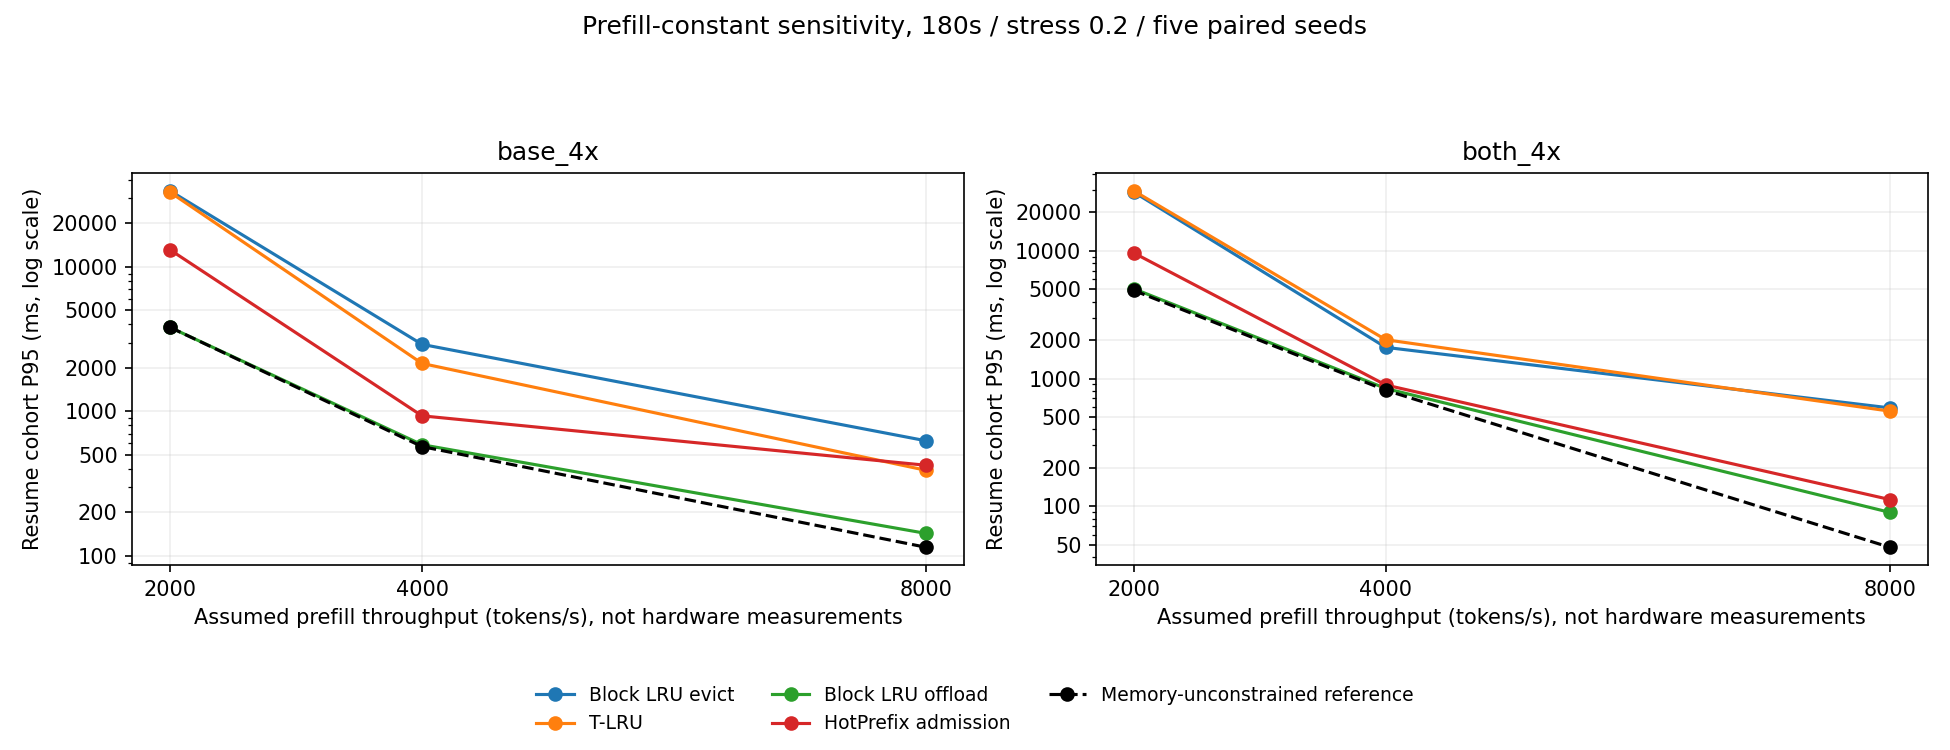

resume_p95_ms  ...  prefill_measurement_busy_pct
prefill_rate variant                             ...                              
2000         hotprefix_admission       9632.261  ...                        75.761
             pin_all                   4903.000  ...                        65.290
             prefix_lru_evict         28863.805  ...                        82.659
             prefix_lru_offload        5051.400  ...                        65.289
             tlru                     29531.516  ...                        83.095
4000         hotprefix_admission        891.359  ...                        33.513
             pin_all                    810.797  ...                        32.689
             prefix_lru_evict          1756.515  ...                        44.367
             prefix_lru_offload         837.041  ...                        32.689
             tlru                      2015.214  ...                        45.417
8000         hotprefix_admission        113.052  ...                        16.740
             pin_all                     47.809  ...                        16.351
             prefix_lru_evict           589.730  ...                        21.973
             prefix_lru_offload          89.732  ...                        16.351
             tlru                       556.419  ...                        22.601

[15 rows x 3 columns]

In [8]:
display(Image(filename=str(ROOT / "docs/figures/week11_revision_prefill.png")))
prefill_cases = audit[(audit.suite == "prefill") & (audit.condition == "both_4x")]
display(prefill_cases.groupby(["prefill_rate", "variant"])[
    ["resume_p95_ms", "normal_p95_ttft_ms", "prefill_measurement_busy_pct"]].mean().round(3))

## 8. 정책별로 어떤 피드백을 줄 수 있는가?

아래는 초기 기본 환경의 참조 격차와 이번 검증 범위를 연결한 판단이다. 기존 7개는 재분석을 한 것이며 추가 격자에서 확인한 것처럼 확대하지 않는다. 수치가 낮다는 사실과 정책의 작동 원리·실제 적용 가능성을 구분한다.

In [9]:
feedback = {
    "pin_all": "GPU가 충분한 참조. 기존 4GiB의 확장 부하 성능을 다시 검증한 것은 아님",
    "evict_recompute": "즉시 삭제 극단의 기존 기준. 부분 회수 block evict와 엔진을 구분",
    "fixed_ttl": "3초 유지의 초기 관측. TTL 변화와 복귀 분포의 일반적 최적성은 미검증",
    "lru_offload": "기본 환경의 참조 격차가 작음. 새 block offload의 확장 결과와 구분",
    "duration_aware": "oracle 대기시간 참조. 예측 오차·30% 기준 변경은 미평가",
    "watermark_offload": "상한 제약 충족과 서비스 이득을 분리. 추가 확장 조건은 미평가",
    "pin_all_capped": "입장 상한만의 효과를 보는 대조. 추가 확장 조건은 미평가",
    "prefix_lru_evict": "같은 GPU-only 부분 회수 기준선. 재계산과 FIFO 대기를 함께 확인",
    "tlru": "조건별 GPU-only 개선과 느린 전송 영역의 이득. 전체 TTFT 200ms 보장은 아님",
    "prefix_lru_offload": "빠른 전송에서 참조에 가까움. 극단적으로 느린 전송의 거절도 확인",
    "hotprefix_admission": "큰 CPU에서는 빈도 필터가 지배. 일부 중간 전송에서 이득; 공유 prefix는 미검증"}
feedback_table = headroom[headroom.setting == "180s_02"][
    ["variant", "resume_p95_ms", "resume_p95_ms_gap_ms"]].copy()
feedback_table["이번 평가 범위"] = feedback_table.variant.map(
    lambda p: "확장 조건 새 replay" if p in CORE else
              "기존 결과 재분석 + 비제약 참조" if p == "pin_all" else "기존 결과 재분석")
feedback_table["판단"] = feedback_table.variant.map(feedback)
with pd.option_context("display.max_colwidth", None):
    display(feedback_table.replace({"variant": LABELS}).round(3))

,variant,resume_p95_ms,resume_p95_ms_gap_ms,이번 평가 범위,판단
0,Duration-Aware,183.159,16.951,기존 결과 재분석,oracle 대기시간 참조. 예측 오차·30% 기준 변경은 미평가
1,Evict/Recompute,1097.672,931.464,기존 결과 재분석,즉시 삭제 극단의 기존 기준. 부분 회수 block evict와 엔진을 구분
2,Fixed TTL,1034.039,867.832,기존 결과 재분석,3초 유지의 초기 관측. TTL 변화와 복귀 분포의 일반적 최적성은 미검증
3,HotPrefix admission,280.232,114.024,확장 조건 새 replay,큰 CPU에서는 빈도 필터가 지배. 일부 중간 전송에서 이득; 공유 prefix는 미검증
4,Legacy LRU offload,196.448,30.240,기존 결과 재분석,기본 환경의 참조 격차가 작음. 새 block offload의 확장 결과와 구분
5,Pin-All,23180.009,23013.801,기존 결과 재분석 + 비제약 참조,GPU가 충분한 참조. 기존 4GiB의 확장 부하 성능을 다시 검증한 것은 아님
6,Capped Pin-All,25587.319,25421.111,기존 결과 재분석,입장 상한만의 효과를 보는 대조. 추가 확장 조건은 미평가
7,Block LRU evict,547.266,381.059,확장 조건 새 replay,같은 GPU-only 부분 회수 기준선. 재계산과 FIFO 대기를 함께 확인
8,Block LRU offload,184.149,17.941,확장 조건 새 replay,빠른 전송에서 참조에 가까움. 극단적으로 느린 전송의 거절도 확인
9,T-LRU,450.189,283.981,확장 조건 새 replay,조건별 GPU-only 개선과 느린 전송 영역의 이득. 전체 TTFT 200ms 보장은 아님


## 9. 현재 결론과 다음 실험

1. **기본 환경의 offload에는 개선 여유가 작았다.** 기존 180초·0.2/s의 비제약 참조 166.2ms와 block offload 184.1ms의 차이를 먼저 보아야 한다.
2. **환경·부하에 따라 유리한 보관 방식이 달라졌다.** 장기 base_4x·0.3/s에서 빠른 PCIe는 block offload, 중간 속도는 HotPrefix, 더 느린 속도는 T-LRU의 평균 복귀가 낮았다. 대표 사례이며 다른 조건의 CI와 완료율을 함께 본다.
3. **초기 개선율은 특정 조건의 값이다.** 짧은 9조건 평균의 T-LRU 17.7%를 장기 전체의 개선율로 쓰지 않는다. 보관량 배분·재계산·대기열을 나눠 해석한다.
4. **HotPrefix 전체·미래 재사용 예측의 검증은 남아 있다.** 현재는 중간 복귀가 보장되고 공유 prefix가 없다. 미복귀를 넣으려면 마지막 턴 즉시 해제와 다른 KV 생명주기가 필요하다.

다음 순서는 **상수 실측 → 대표 역전 구간 재확인 → 미복귀/도구별 대기 또는 공유 prefix 모델 → 실제 엔진 한 지점 검증**이다. 기존 정책에 대해 추가 조건의 결론이 필요하면 기존 엔진 안에서 별도 비교한다.

[통합 보고서](../docs/week11_experiment.md) · [초기 정책 비교](week11_policy_review.ipynb) · [전체 실험 목록](../docs/experiment_overview.md)